<a href="https://colab.research.google.com/github/varshayinithangaraju30-lgtm/customer-segmentation-kmeans/blob/main/integration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cluster
1    7
0    7
2    6
Name: count, dtype: int64
          Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                  
0        27.0                20.0                    83.6
1        49.7                20.0                    16.4
2        22.7                16.0                    53.2


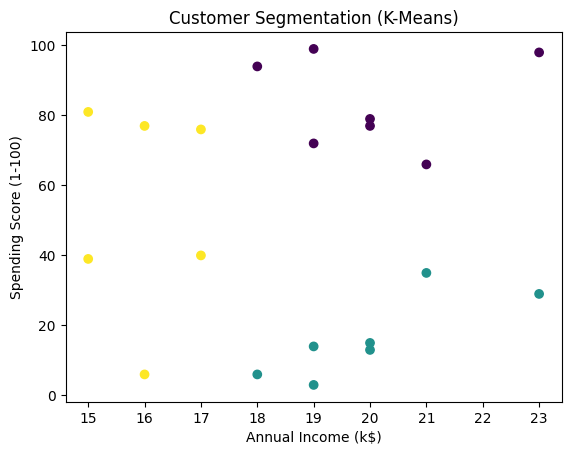

All 4 end-to-end tests passed ✅


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

URL = "https://raw.githubusercontent.com/varshayinithangaraju30-lgtm/customer-segmentation-kmeans/main/Mall_Customers.csv"
FEATURES = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

def load_data(path):
    df = pd.read_csv(path)
    if df.empty:
        raise ValueError("Input data is empty")
    return df

def preprocess(df, features=FEATURES):
    missing = [c for c in features if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")
    df = df.copy().drop_duplicates().dropna(subset=features)
    X = StandardScaler().fit_transform(df[features])
    return df, X

def validate(X, n_clusters):
    if np.isnan(X).any() or not np.isfinite(X).all():
        raise ValueError("Data has NaN or infinite values")
    if n_clusters < 1 or n_clusters > X.shape[0]:
        raise ValueError("n_clusters must be between 1 and number of rows")

def cluster(X, n_clusters=3):
    model = KMeans(n_clusters=n_clusters, init="k-means++", n_init=10, random_state=42)
    return model, model.fit_predict(X)

def run_pipeline(path, n_clusters=3):
    df = load_data(path)
    df, X = preprocess(df)
    validate(X, n_clusters)
    model, labels = cluster(X, n_clusters)
    df["Cluster"] = labels
    return df, model

result, model = run_pipeline(URL, n_clusters=3)
print(result["Cluster"].value_counts())
print(result.groupby("Cluster")[FEATURES].mean().round(1))

plt.scatter(result["Annual Income (k$)"], result["Spending Score (1-100)"], c=result["Cluster"])
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Segmentation (K-Means)")
plt.show()

def test_end_to_end():
    df, _ = run_pipeline(URL, 3)
    assert "Cluster" in df.columns
    assert df["Cluster"].nunique() == 3
    assert df["Cluster"].isna().sum() == 0

def test_same_result_each_run():
    a, _ = run_pipeline(URL, 3)
    b, _ = run_pipeline(URL, 3)
    assert (a["Cluster"] == b["Cluster"]).all()

def test_bad_k():
    try:
        run_pipeline(URL, 1000)
        assert False
    except ValueError:
        pass

def test_missing_column():
    try:
        preprocess(pd.DataFrame({"Age": [1, 2, 3]}))
        assert False
    except ValueError:
        pass

test_end_to_end()
test_same_result_each_run()
test_bad_k()
test_missing_column()
print("All 4 end-to-end tests passed ✅")